# Лабораторная работа 02. Часть 1 — базовый конвейер Pandas

**ФИО:** Мельников Артем Иванович  
**Группа:** ЕТ-216

Данные взяты из задания преподавателя. Реализация и пояснения написаны самостоятельно по требованиям PDF. Цель — пройти путь от исходной таблицы до аналитического вывода.

## 3. Формирование CSV

Одна строка — один заказ. Пустое время доставки обозначено `np.nan`. Индекс DataFrame в CSV не сохраняем.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
raw_data = {
 'order_id': list(range(1001, 1016)),
 'channel': ['site','app','app','marketplace','site','app','site','marketplace','app','site','marketplace','app','site','site','marketplace'],
 'order_sum': [1200,2500,1800,3200,900,1500,2800,45000,2100,1700,3600,1100,2400,1900,3300],
 'delivery_time': [25,np.nan,40,55,20,30,np.nan,70,35,45,50,18,27,np.nan,60],
 'rating': [5,4,5,3,5,4,2,1,5,4,3,5,4,5,2]
}
df = pd.DataFrame(raw_data)
df.to_csv('online_store_orders.csv', index=False)
display(df)

,order_id,channel,order_sum,delivery_time,rating
0,1001,site,1200,25.0,5
1,1002,app,2500,NaN,4
2,1003,app,1800,40.0,5
3,1004,marketplace,3200,55.0,3
4,1005,site,900,20.0,5
5,1006,app,1500,30.0,4
6,1007,site,2800,NaN,2
7,1008,marketplace,45000,70.0,1
8,1009,app,2100,35.0,5
9,1010,site,1700,45.0,4


## 4. Загрузка и структура

Все последующие действия выполняем с таблицей, прочитанной из CSV.

In [2]:
store_df = pd.read_csv('online_store_orders.csv')
display(store_df.head())
display(store_df.tail())
print('Строк и столбцов:', store_df.shape)
print('Столбцы:', store_df.columns.tolist())
store_df.info()

,order_id,channel,order_sum,delivery_time,rating
0,1001,site,1200,25.0,5
1,1002,app,2500,NaN,4
2,1003,app,1800,40.0,5
3,1004,marketplace,3200,55.0,3
4,1005,site,900,20.0,5


,order_id,channel,order_sum,delivery_time,rating
10,1011,marketplace,3600,50.0,3
11,1012,app,1100,18.0,5
12,1013,site,2400,27.0,4
13,1014,site,1900,NaN,5
14,1015,marketplace,3300,60.0,2


Строк и столбцов: (15, 5)
Столбцы: ['order_id', 'channel', 'order_sum', 'delivery_time', 'rating']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       15 non-null     int64  
 1   channel        15 non-null     object 
 2   order_sum      15 non-null     int64  
 3   delivery_time  12 non-null     float64
 4   rating         15 non-null     int64  
dtypes: float64(1), int64(3), object(1)
memory usage: 732.0+ bytes


## 5. Выборка и фильтрация

У iloc правая граница не включается: 3:8 возвращает индексы 3–7. Скобки отделяют условия, & объединяет их по строкам.

In [3]:
display(store_df[['order_sum','delivery_time']])
slice_df = store_df.iloc[3:8, [2,3]]
display(slice_df)
premium_orders = store_df.loc[(store_df['order_sum'] > 2000) & (store_df['rating'] == 5)]
display(premium_orders)

,order_sum,delivery_time
0,1200,25.0
1,2500,NaN
2,1800,40.0
3,3200,55.0
4,900,20.0
5,1500,30.0
6,2800,NaN
7,45000,70.0
8,2100,35.0
9,1700,45.0


,order_sum,delivery_time
3,3200,55.0
4,900,20.0
5,1500,30.0
6,2800,NaN
7,45000,70.0


,order_id,channel,order_sum,delivery_time,rating
8,1009,app,2100,35.0,5


## 6. Качество и статистика

Пропуски не заменяем: среднее и медиана доставки вычисляются по известным значениям. Идентификатор числовой, но его среднее не имеет делового смысла.

In [4]:
display(store_df.isna().sum().rename('Пропуски'))
display(store_df.describe())
mean_delivery = store_df['delivery_time'].mean()
median_delivery = store_df['delivery_time'].median()
print(f'Среднее время: {mean_delivery:.2f}; медиана: {median_delivery:.2f}')
display(store_df['rating'].value_counts().sort_index().rename('Число заказов'))

,Пропуски
order_id,0
channel,0
order_sum,0
delivery_time,3
rating,0


,order_id,order_sum,delivery_time,rating
count,15.000000,15.00000,12.000000,15.000000
mean,1008.000000,5000.00000,39.583333,3.800000
std,4.472136,11096.33144,16.654010,1.320173
min,1001.000000,900.00000,18.000000,1.000000
25%,1004.500000,1600.00000,26.500000,3.000000
50%,1008.000000,2100.00000,37.500000,4.000000
75%,1011.500000,3000.00000,51.250000,5.000000
max,1015.000000,45000.00000,70.000000,5.000000


Среднее время: 39.58; медиана: 37.50


,Число заказов
rating,
1,1
2,2
3,2
4,4
5,6


## 7. Группировка и влияние крупного заказа

Порог высокой стоимости строго больше 3000. Сравнение без максимума служит проверкой чувствительности; исходный заказ не удаляем.

In [5]:
store_df['is_high_value'] = store_df['order_sum'] > 3000
display(store_df[['order_id','order_sum','is_high_value']])
channel_stats = store_df.groupby('channel')['order_sum'].mean().sort_values(ascending=False)
display(channel_stats.rename('Средняя сумма'))
without_max = store_df.drop(index=store_df['order_sum'].idxmax())
display(pd.concat([channel_stats.rename('Все заказы'), without_max.groupby('channel')['order_sum'].mean().rename('Без максимума')],axis=1))
print('Средняя общая:', store_df['order_sum'].mean())
print('Средняя без максимума:', without_max['order_sum'].mean())

,order_id,order_sum,is_high_value
0,1001,1200,False
1,1002,2500,False
2,1003,1800,False
3,1004,3200,True
4,1005,900,False
5,1006,1500,False
6,1007,2800,False
7,1008,45000,True
8,1009,2100,False
9,1010,1700,False


,Средняя сумма
channel,
marketplace,13775.000000
site,1816.666667
app,1800.000000


,Все заказы,Без максимума
channel,,
marketplace,13775.000000,3366.666667
site,1816.666667,1816.666667
app,1800.000000,1800.000000


Средняя общая: 5000.0
Средняя без максимума: 2142.8571428571427


## 8. Итоговый аналитический вывод

Вывод строится из рассчитанных значений и обновляется при повторном запуске.

In [6]:
channel_text = '; '.join(f'{key}: {value:.2f} руб.' for key,value in channel_stats.items())
display(Markdown(f"В наборе {len(store_df)} заказов, у {store_df['delivery_time'].isna().sum()} не указано время доставки. Среднее время доставки равно {mean_delivery:.2f}, медианное — {median_delivery:.2f} в единицах исходного задания; среднее на {mean_delivery-median_delivery:.2f} выше медианы. Средняя сумма по каналам: {channel_text}. Заказов дороже 3000 рублей — {store_df['is_high_value'].sum()}. Заказ на 45000 рублей поднимает общую среднюю с {without_max['order_sum'].mean():.2f} до {store_df['order_sum'].mean():.2f} руб., поэтому лидерство marketplace по среднему чеку нельзя оценивать без учёта этого наблюдения."))

В наборе 15 заказов, у 3 не указано время доставки. Среднее время доставки равно 39.58, медианное — 37.50 в единицах исходного задания; среднее на 2.08 выше медианы. Средняя сумма по каналам: marketplace: 13775.00 руб.; site: 1816.67 руб.; app: 1800.00 руб.. Заказов дороже 3000 рублей — 4. Заказ на 45000 рублей поднимает общую среднюю с 2142.86 до 5000.00 руб., поэтому лидерство marketplace по среднему чеку нельзя оценивать без учёта этого наблюдения.

## 11. Дополнительно: гистограмма

Слева все заказы, справа увеличенный масштаб основной массы без максимума. Подписи показывают разные выборки.

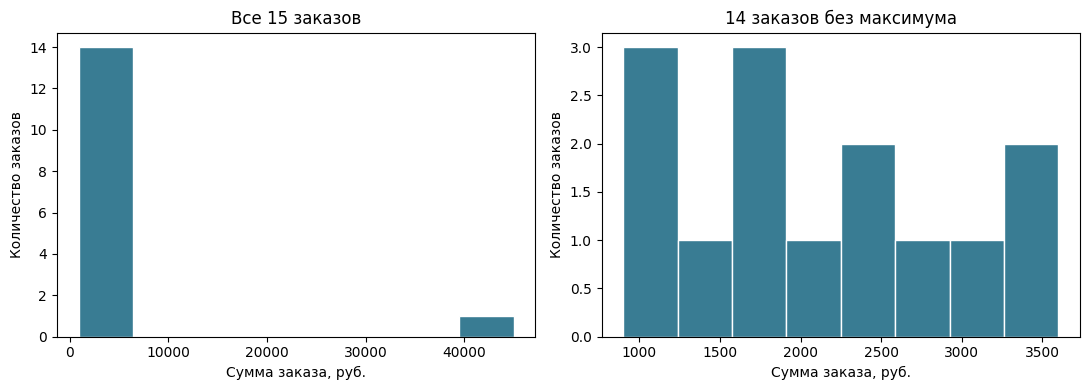

In [7]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax,series,title in [(axes[0],store_df['order_sum'],'Все 15 заказов'),(axes[1],without_max['order_sum'],'14 заказов без максимума')]:
 ax.hist(series,bins=8,color='#397c93',edgecolor='white')
 ax.set(title=title,xlabel='Сумма заказа, руб.',ylabel='Количество заказов')
fig.tight_layout()
plt.show()

Большая сумма расширяет горизонтальную шкалу, поэтому обычные заказы на первом графике сжимаются в узкой области. Второй график позволяет рассмотреть их распределение, но не заменяет анализ полного набора.